In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Create an in-memory relational database
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

print("SQLite database created successfully!")


SQLite database created successfully!


In [2]:
cursor.executescript("""
CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    name TEXT NOT NULL,
    city TEXT NOT NULL
);

CREATE TABLE products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT NOT NULL,
    category TEXT NOT NULL,
    price REAL NOT NULL
);

CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER NOT NULL,
    order_date TEXT NOT NULL,
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

CREATE TABLE order_items (
    order_id INTEGER NOT NULL,
    product_id INTEGER NOT NULL,
    quantity INTEGER NOT NULL,
    FOREIGN KEY (order_id) REFERENCES orders(order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id)
);
""")

print("All four tables created.")


All four tables created.


In [3]:
customers = [
    (1, "Anita", "Ongole"),
    (2, "Rahul", "Chennai"),
    (3, "Meena", "Vijayawada"),
    (4, "Arjun", "Ongole"),
    (5, "Priya", "Hyderabad")
]

products = [
    (101, "Wireless Mouse", "Electronics", 850),
    (102, "Keyboard", "Electronics", 1400),
    (103, "Notebook", "Stationery", 120),
    (104, "Backpack", "Accessories", 950),
    (105, "Water Bottle", "Accessories", 500),
    (106, "USB Cable", "Electronics", 300)
]

orders = [
    (1001, 1, "2026-09-01"),
    (1002, 2, "2026-09-02"),
    (1003, 1, "2026-09-04"),
    (1004, 3, "2026-09-05"),
    (1005, 4, "2026-09-07"),
    (1006, 5, "2026-09-08"),
    (1007, 2, "2026-09-10")
]

order_items = [
    (1001, 101, 2), (1001, 103, 3),
    (1002, 102, 1), (1002, 106, 2),
    (1003, 104, 1), (1003, 105, 2),
    (1004, 103, 5), (1004, 105, 1),
    (1005, 102, 2), (1005, 101, 1),
    (1006, 104, 2), (1006, 106, 3),
    (1007, 101, 1), (1007, 105, 1)
]

cursor.executemany("INSERT INTO customers VALUES (?, ?, ?)", customers)
cursor.executemany("INSERT INTO products VALUES (?, ?, ?, ?)", products)
cursor.executemany("INSERT INTO orders VALUES (?, ?, ?)", orders)
cursor.executemany("INSERT INTO order_items VALUES (?, ?, ?)", order_items)
conn.commit()

print("Sample data inserted.")


Sample data inserted.


In [4]:
products_df = pd.read_sql_query(
    "SELECT * FROM products ORDER BY product_id",
    conn
)
products_df


,product_id,product_name,category,price
0,101,Wireless Mouse,Electronics,850.0
1,102,Keyboard,Electronics,1400.0
2,103,Notebook,Stationery,120.0
3,104,Backpack,Accessories,950.0
4,105,Water Bottle,Accessories,500.0
5,106,USB Cable,Electronics,300.0


In [5]:
order_revenue = pd.read_sql_query("""
SELECT
    o.order_id,
    o.order_date,
    c.name AS customer,
    ROUND(SUM(oi.quantity * p.price), 2) AS order_total
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY o.order_id, o.order_date, c.name
ORDER BY order_total DESC;
""", conn)

order_revenue


,order_id,order_date,customer,order_total
0,1005,2026-09-07,Arjun,3650.0
1,1006,2026-09-08,Priya,2800.0
2,1001,2026-09-01,Anita,2060.0
3,1002,2026-09-02,Rahul,2000.0
4,1003,2026-09-04,Anita,1950.0
5,1007,2026-09-10,Rahul,1350.0
6,1004,2026-09-05,Meena,1100.0


In [6]:
customer_spending = pd.read_sql_query("""
SELECT
    c.customer_id,
    c.name,
    c.city,
    ROUND(SUM(oi.quantity * p.price), 2) AS total_spent
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY c.customer_id, c.name, c.city
ORDER BY total_spent DESC;
""", conn)

customer_spending


,customer_id,name,city,total_spent
0,1,Anita,Ongole,4010.0
1,4,Arjun,Ongole,3650.0
2,2,Rahul,Chennai,3350.0
3,5,Priya,Hyderabad,2800.0
4,3,Meena,Vijayawada,1100.0


In [7]:
product_sales = pd.read_sql_query("""
SELECT
    p.product_name,
    p.category,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM products p
JOIN order_items oi ON p.product_id = oi.product_id
GROUP BY p.product_id, p.product_name, p.category
ORDER BY units_sold DESC, revenue DESC;
""", conn)

product_sales


,product_name,category,units_sold,revenue
0,Notebook,Stationery,8,960.0
1,USB Cable,Electronics,5,1500.0
2,Wireless Mouse,Electronics,4,3400.0
3,Water Bottle,Accessories,4,2000.0
4,Keyboard,Electronics,3,4200.0
5,Backpack,Accessories,3,2850.0


In [8]:
category_revenue = pd.read_sql_query("""
SELECT
    p.category,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM products p
JOIN order_items oi ON p.product_id = oi.product_id
GROUP BY p.category
ORDER BY revenue DESC;
""", conn)

category_revenue


,category,units_sold,revenue
0,Electronics,12,9100.0
1,Accessories,7,4850.0
2,Stationery,8,960.0


In [9]:
selected_city = "Ongole"

city_customers = pd.read_sql_query(
    "SELECT customer_id, name, city FROM customers WHERE city = ? ORDER BY name",
    conn,
    params=(selected_city,)
)

city_customers


,customer_id,name,city
0,1,Anita,Ongole
1,4,Arjun,Ongole


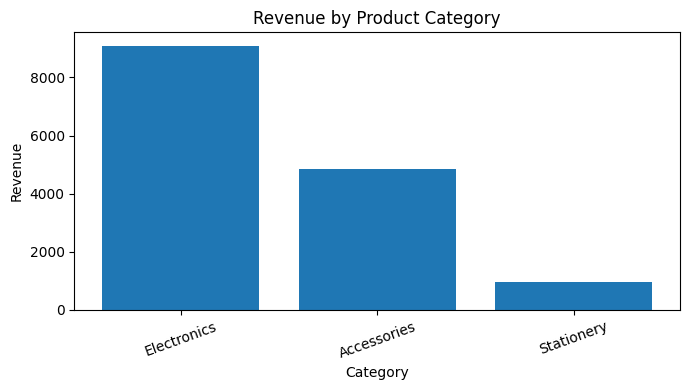

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(category_revenue["category"], category_revenue["revenue"])
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [10]:
# Final summary
total_revenue = pd.read_sql_query(
    "SELECT ROUND(SUM(oi.quantity * p.price), 2) AS total_revenue "
    "FROM order_items oi JOIN products p ON oi.product_id = p.product_id",
    conn
).iloc[0, 0]

top_product = product_sales.iloc[0]["product_name"]
top_customer = customer_spending.iloc[0]["name"]

print(f"Total revenue: {total_revenue}")
print(f"Top-selling product by units: {top_product}")
print(f"Highest-spending customer: {top_customer}")


Total revenue: 14910.0
Top-selling product by units: Notebook
Highest-spending customer: Anita
